# 05 — Clustering Analysis

The objective of this stage is to discover groups of accounts with similar behavioral characteristics using unsupervised clustering.

We will investigate:
1. K-means clustering.
2. Density-based clustering.
3. Hierarchical clustering.
4. Cluster evaluation and interpretation.

We will also compare different feature configurations to evaluate the influence of potentially unreliable or redundant features.

## A. Dataset Preparation

We load the standardized account-level features and prepare the candidate feature sets.

Account identifiers are excluded from clustering, while IO/control labels are preserved separately for external evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# Load the standardized dataset
DATA_PATH = Path("data_processed/df_clustering_features.csv.gz")

df_clustering = pd.read_csv(
    DATA_PATH,
    dtype={
        "ioCountry": "string",
        "accountid": "string"
    }
)

account_keys = ["ioCountry", "accountid"]

# Numerical clustering features
features_all = [
    col for col in df_clustering.columns
    if col not in account_keys
]

print("Account profiles:", len(df_clustering))
print("Numerical features:", len(features_all))
print("Missing values:", df_clustering[features_all].isna().sum().sum())

Account profiles: 86525
Numerical features: 14
Missing values: 0


In [3]:
# Define candidate feature sets
candidate_feature_sets = {
    "all_features": features_all,

    "no_intensity": [
        col for col in features_all
        if col != "posting_intensity"
    ],

    "no_activity": [
        col for col in features_all
        if col not in ["post_count", "posting_intensity"]
    ],

    "no_mention": [
        col for col in features_all
        if col != "mention_ratio"
    ]
}

# Create numerical matrices
X_candidates = {
    name: df_clustering[columns].to_numpy(dtype=np.float32)
    for name, columns in candidate_feature_sets.items()
}

# Preserve account identifiers
account_ids = df_clustering[account_keys].copy()

# Verify
for name, X in X_candidates.items():
    print(f"{name}: {X.shape}")

all_features: (86525, 14)
no_intensity: (86525, 13)
no_activity: (86525, 12)
no_mention: (86525, 13)


## B. K-means Clustering

### B.1 — Choosing the Number of Clusters

We apply K-means to the complete 14-feature dataset and test different numbers of clusters.

We use inertia (Elbow Method) and Silhouette Score to assess clustering quality and help select an appropriate value of k.

To reduce computational cost, Silhouette Score is calculated on a fixed random sample of accounts, while K-means is trained on all account profiles.

In [12]:
# Use all 14 features as our baseline
X = X_candidates["all_features"]

# Test different numbers of clusters
k_values = range(2, 9)

# Fixed sample for silhouette evaluation
rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(X),
    size=min(2000, len(X)),
    replace=False
)

results = []

for k in k_values:

    # Train K-means on all accounts
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    # Calculate silhouette using the same sample
    silhouette = silhouette_score(
        X[sample_idx],
        labels[sample_idx]
    )

    results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette
    })

    print(f"k={k} completed")

# Display results
k_results = pd.DataFrame(results)

display(k_results.round(3))

k=2 completed
k=3 completed
k=4 completed
k=5 completed
k=6 completed
k=7 completed
k=8 completed


,k,Inertia,Silhouette Score
0,2,1041293.938,0.144
1,3,927587.750,0.150
2,4,828184.062,0.168
3,5,762661.125,0.159
4,6,720032.938,0.158
5,7,687803.188,0.154
6,8,660204.125,0.137


### B.2 — K-means Parameter Evaluation
The highest sampled Silhouette Score is obtained at k = 4 (0.168). However, the relatively low score suggests weak cluster separation.

We visualize both metrics to assess whether k = 4 is a reasonable starting configuration.

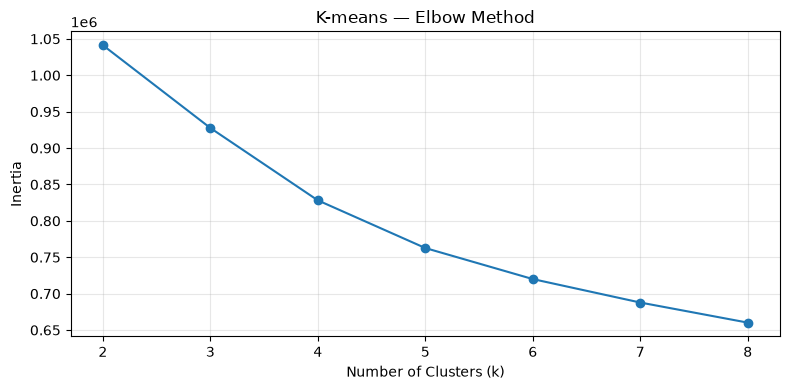

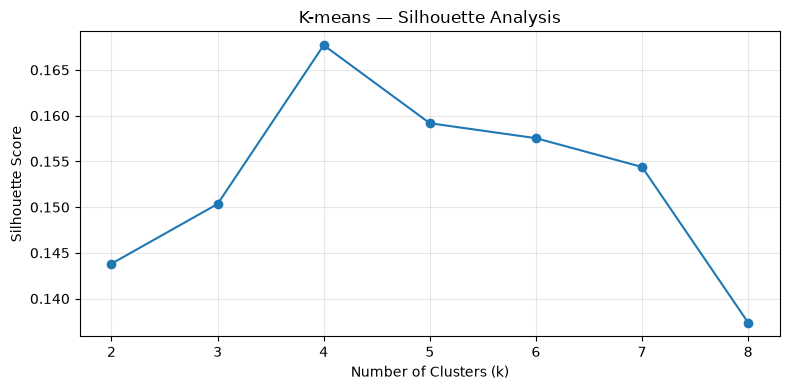

In [13]:
# Elbow Method
plt.figure(figsize=(8, 4))

plt.plot(
    k_results["k"],
    k_results["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-means — Elbow Method")
plt.xticks(k_results["k"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Silhouette Score
plt.figure(figsize=(8, 4))

plt.plot(
    k_results["k"],
    k_results["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-means — Silhouette Analysis")
plt.xticks(k_results["k"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### B.2 — K-means Parameter Evaluation Results
The highest Silhouette Score is obtained at **k = 4 (0.168)**, although the relatively low score suggests weak cluster separation.

We therefore select k = 4 as an initial configuration for further analysis and cluster interpretation.

### B.3 — Cluster Size Analysis

We apply K-means with k = 4 to the complete standardized dataset.

We examine the number and proportion of accounts assigned to each cluster to identify possible imbalances or very small clusters.

In [14]:
# Train K-means with k = 4
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

X = X_candidates["all_features"]

cluster_labels = kmeans.fit_predict(X)

# Count accounts in each cluster
cluster_sizes = (
    pd.Series(cluster_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

cluster_summary = pd.DataFrame({
    "Accounts": cluster_sizes,
    "Percentage (%)": (
        cluster_sizes / len(X) * 100
    ).round(2)
})

display(cluster_summary)

print("Total accounts:", cluster_sizes.sum())

,Accounts,Percentage (%)
Cluster,,
0,32457,37.51
1,11205,12.95
2,21910,25.32
3,20953,24.22


Total accounts: 86525


#### B.3 — Cluster Size Results

K-means divided the 86,525 accounts into four clusters of different sizes.

Cluster 0 contains the largest proportion of accounts (37.51%), while Cluster 1 contains the smallest (12.95%).

No extremely small clusters were identified. Further analysis of cluster centroids is needed to understand the behavioral differences between clusters.

### B.4 — Cluster Centroid Analysis

We examine the centroids of the four clusters to identify their main behavioral characteristics.

Since the features are standardized, positive centroid values indicate above-average characteristics, while negative values indicate below-average characteristics.

In [15]:
# Extract cluster centroids
centroid_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features_all,
    index=[f"Cluster {i}" for i in range(4)]
)

# Display centroids with features as rows
display(centroid_df.T.round(2))

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
post_count,-0.24,1.27,0.17,-0.48
posting_intensity,0.06,-0.75,0.46,-0.18
follower_count,0.13,-0.25,0.45,-0.54
following_count,0.26,-0.14,0.31,-0.65
account_age_days,0.41,-0.51,-0.07,-0.29
activity_lifespan_days,-0.38,2.39,-0.39,-0.28
repost_ratio,0.98,-0.14,-0.46,-0.96
reply_ratio,-0.36,-0.14,1.05,-0.48
mention_ratio,0.82,-0.25,0.10,-1.24
hashtag_ratio,0.06,-0.22,-0.65,0.69


#### B.4 — Cluster Centroid Results

The four clusters exhibit different behavioral characteristics:

- **Cluster 0:** High reposting and mentioning activity.
- **Cluster 1:** High posting volume, longer observed activity lifespan, and greater language/application diversity.
- **Cluster 2:** Higher reply activity and posting intensity, with fewer URLs and hashtags.
- **Cluster 3:** Higher hashtag usage, with relatively low reposting, mentioning, and follower/following counts.

These results suggest that K-means identified distinct behavioral tendencies. However, the relatively low Silhouette Score (0.168) indicates weak separation between clusters.

### B.5 — Cluster Profiles in Original Units

We examine median feature values for each cluster using the original account-level data.

This allows us to interpret the clusters in meaningful units, such as the number of posts, activity lifespan in days, and interaction ratios.

In [16]:
# Load original, unscaled account features
ORIGINAL_PATH = Path("data_processed/df_account_features_eda.csv.gz")

df_original = pd.read_csv(
    ORIGINAL_PATH,
    dtype={"ioCountry": "string", "accountid": "string"}
)

# Match cluster assignments to account identifiers
cluster_assignments = account_ids.copy()
cluster_assignments["Cluster"] = cluster_labels

df_profiles = df_original.merge(
    cluster_assignments,
    on=account_keys,
    how="inner",
    validate="one_to_one"
)

# Select important features for interpretation
profile_features = [
    "post_count",
    "posting_intensity",
    "activity_lifespan_days",
    "repost_ratio",
    "reply_ratio",
    "mention_ratio",
    "hashtag_ratio",
    "url_ratio",
    "unique_languages"
]

# Median characteristics per cluster
cluster_profiles = (
    df_profiles
    .groupby("Cluster")[profile_features]
    .median()
)

display(cluster_profiles.T.round(2))

Cluster,0,1,2,3
post_count,16.00,173.00,34.00,8.00
posting_intensity,15.00,1.20,33.00,6.00
activity_lifespan_days,0.00,169.00,0.00,0.00
repost_ratio,0.95,0.32,0.20,0.00
reply_ratio,0.00,0.02,0.27,0.00
mention_ratio,1.00,0.53,0.68,0.00
hashtag_ratio,0.52,0.45,0.27,0.99
url_ratio,0.74,0.43,0.21,0.95
unique_languages,1.00,3.00,2.00,1.00


### B.6 — Cluster Visualization

We visualize the standardized cluster centroids to better understand the behavioral characteristics of each cluster.

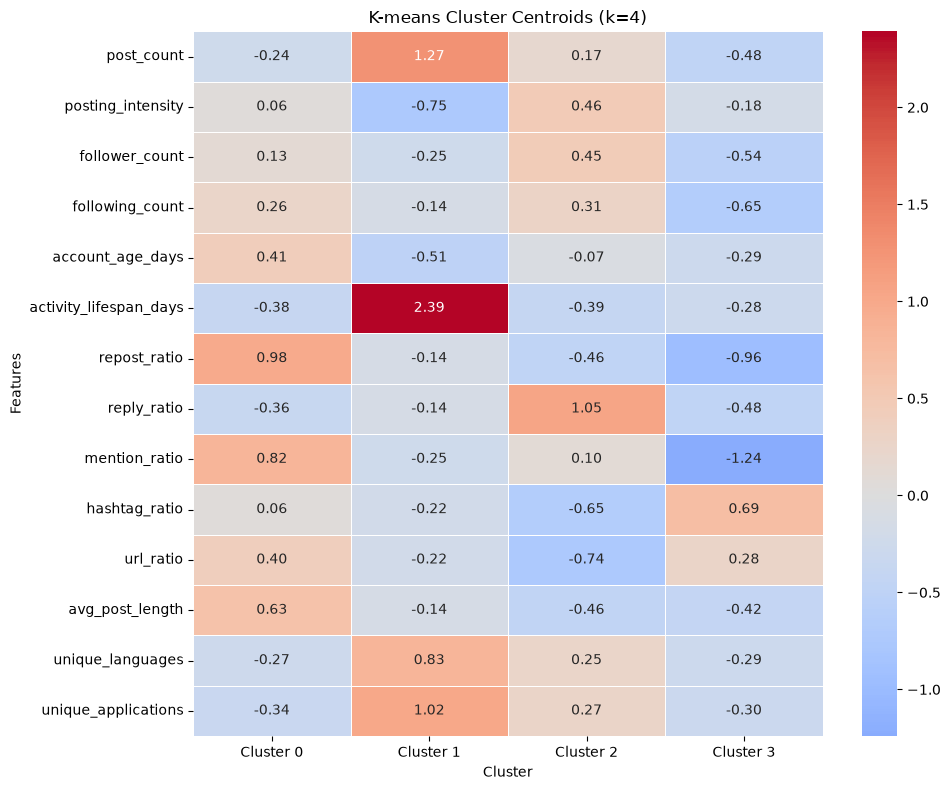

In [17]:
# Visualize the standardized cluster centroids
plt.figure(figsize=(10, 8))

sns.heatmap(
    centroid_df.T,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("K-means Cluster Centroids (k=4)")
plt.xlabel("Cluster")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### B.7 — PCA Cluster Visualization

We use Principal Component Analysis (PCA) to project the 14-dimensional account features into two dimensions.

Each point represents an account, colored according to its K-means cluster.

This visualization helps us examine cluster separation and overlap. However, PCA is used only for visualization; clustering was performed using the original 14-dimensional feature space.

In [18]:
from sklearn.decomposition import PCA

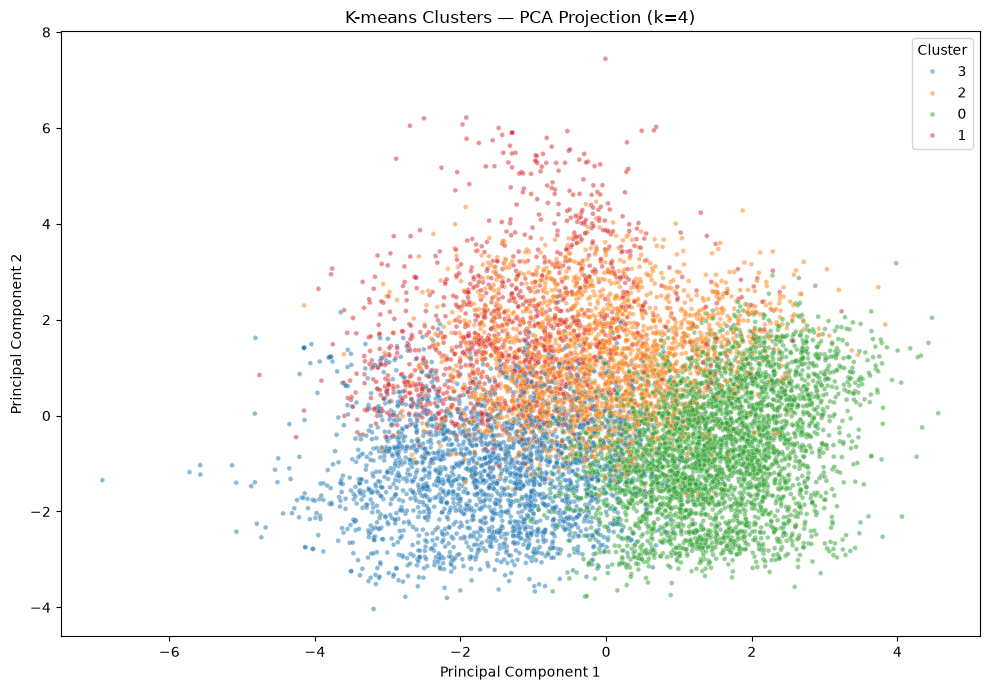

Variance explained by first two PCs: 38.68%


In [19]:
# Use the same 14 features used by K-means
X = X_candidates["all_features"]

# Reduce 14 dimensions to 2
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# Randomly sample 10,000 accounts for visualization
rng = np.random.default_rng(42)

sample_idx = rng.choice(
    len(X),
    size=min(10000, len(X)),
    replace=False
)

# Create visualization dataset
df_pca = pd.DataFrame({
    "PC1": X_pca[sample_idx, 0],
    "PC2": X_pca[sample_idx, 1],
    "Cluster": cluster_labels[sample_idx].astype(str)
})

# Plot clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=12,
    alpha=0.5
)

plt.title("K-means Clusters — PCA Projection (k=4)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by first two PCs:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

#### B.7 — PCA Visualization Results

The PCA visualization shows four clusters occupying partially distinct regions, with considerable overlap.

The first two principal components explain **38.68%** of the total variance, meaning the projection does not fully represent the original 14-dimensional data.

The results are consistent with the relatively low Silhouette Score (0.168), indicating weak cluster separation.

### B.8 — Feature Configuration Comparison

We compare K-means clustering using four feature configurations:

- All 14 numerical features.
- Without posting intensity.
- Without posting intensity and post count.
- Without mention ratio.

We initially keep k = 4 to examine how feature selection affects clustering quality, using the same evaluation sample for all configurations.

In [22]:
# Fixed sample for fair comparison
rng = np.random.default_rng(42)

sample_idx = rng.choice(
    len(df_clustering),
    size=2000,
    replace=False
)

comparison_results = []

for name, X in X_candidates.items():

    model = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(
        X[sample_idx],
        labels[sample_idx]
    )

    comparison_results.append({
        "Configuration": name,
        "Features": X.shape[1],
        "Silhouette Score": score
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(
        "Silhouette Score",
        ascending=False
    ).round(3)
)

,Configuration,Features,Silhouette Score
2,no_activity,12,0.194
1,no_intensity,13,0.180
0,all_features,14,0.168
3,no_mention,13,0.152


### B.9 — K-means Evaluation Without Activity Features

The 12-feature configuration, excluding `post_count` and `posting_intensity`, achieved the highest Silhouette Score (0.194) among the configurations tested at k = 4.

We now evaluate different values of k for this configuration to determine whether four clusters remain a suitable choice.

In [23]:
# Use the 12-feature configuration
X_no_activity = X_candidates["no_activity"]

# Test different numbers of clusters
k_values = range(2, 9)

# Fixed random sample for Silhouette Score
rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(X_no_activity),
    size=2000,
    replace=False
)

results_no_activity = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_no_activity)

    score = silhouette_score(
        X_no_activity[sample_idx],
        labels[sample_idx]
    )

    results_no_activity.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette Score": score
    })

# Display results
k_results_no_activity = pd.DataFrame(results_no_activity)

display(k_results_no_activity.round(3))

,k,Inertia,Silhouette Score
0,2,871112.125,0.164
1,3,766426.312,0.177
2,4,686344.562,0.194
3,5,639980.312,0.155
4,6,597082.250,0.155
5,7,565636.312,0.151
6,8,542904.188,0.149


#### B.9 — Results

The 12-feature configuration achieved its highest Silhouette Score at **k = 4 (0.194)**.

This is higher than the original 14-feature configuration (0.168), suggesting that excluding `post_count` and `posting_intensity` may improve cluster separation.

However, the score remains relatively low, indicating that the clusters are not strongly separated.

### B.10 — Comparing Clustering Configurations

We compare the original 14-feature clustering solution with the 12-feature configuration.

We examine cluster sizes and calculate the Adjusted Rand Index (ARI) to understand how removing posting activity features affects cluster assignments.

In [24]:
# Fit K-means on the 12-feature configuration
kmeans_no_activity = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_no_activity = kmeans_no_activity.fit_predict(
    X_candidates["no_activity"]
)

# Check cluster sizes
sizes_no_activity = (
    pd.Series(labels_no_activity, name="Cluster")
    .value_counts()
    .sort_index()
)

summary_no_activity = pd.DataFrame({
    "Accounts": sizes_no_activity,
    "Percentage (%)": (
        sizes_no_activity / len(labels_no_activity) * 100
    ).round(2)
})

display(summary_no_activity)

# Compare with the original 14-feature clustering
ari = adjusted_rand_score(
    cluster_labels,
    labels_no_activity
)

print(f"ARI between 14-feature and 12-feature solutions: {ari:.3f}")

,Accounts,Percentage (%)
Cluster,,
0,10750,12.42
1,20580,23.79
2,21434,24.77
3,33761,39.02


ARI between 14-feature and 12-feature solutions: 0.838


#### B.10 — Configuration Comparison Results

The 12-feature configuration achieved a higher Silhouette Score (0.194) than the original 14-feature configuration (0.168).

The Adjusted Rand Index between the two solutions is **0.838**, indicating strong agreement in their clustering structures.

Removing `post_count` and `posting_intensity` therefore improved cluster separation while preserving much of the original grouping structure.

### B.11 — Interpretation of the 12-Feature Clusters

We examine the standardized centroids of the 12-feature configuration to identify the behavioral characteristics of its four clusters.

This allows us to compare their interpretation with the original 14-feature solution before selecting a final configuration.

In [25]:
# Extract centroids of the 12-feature K-means solution
centroids_no_activity = pd.DataFrame(
    kmeans_no_activity.cluster_centers_,
    columns=candidate_feature_sets["no_activity"],
    index=[f"Cluster {i}" for i in range(4)]
)

display(centroids_no_activity.T.round(2))

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
follower_count,-0.30,-0.50,0.34,0.18
following_count,-0.15,-0.64,0.24,0.29
account_age_days,-0.53,-0.29,-0.09,0.40
activity_lifespan_days,2.40,-0.25,-0.38,-0.37
repost_ratio,-0.12,-0.99,-0.50,0.96
reply_ratio,-0.14,-0.51,1.12,-0.36
mention_ratio,-0.22,-1.30,0.09,0.80
hashtag_ratio,-0.27,0.76,-0.69,0.06
url_ratio,-0.27,0.34,-0.82,0.40
avg_post_length,-0.17,-0.39,-0.52,0.62


#### B.11 — Results

The 12-feature configuration identifies four main behavioral groups:

- **Cluster 0:** Longer observed activity lifespan and greater language/application diversity.
- **Cluster 1:** Higher hashtag usage with low reposting and mentioning activity.
- **Cluster 2:** Higher reply activity with fewer URLs and hashtags.
- **Cluster 3:** Higher reposting and mentioning activity.

These characteristics are similar to those identified using all 14 features.

Combined with the higher Silhouette Score (0.194) and strong agreement between the two solutions (ARI = 0.838), the 12-feature configuration is a promising choice for further evaluation.

### B.12 — IO vs. Control Cluster Composition

We compare the four clusters obtained using the 12-feature configuration with the original IO/control labels.

The labels were excluded during clustering and are used only for external evaluation.

We examine the number and proportion of IO and control accounts in each cluster.

In [27]:
# Load the original account labels
LABELS_PATH = DATA_PATH.parent / "df_account_labels.csv.gz"

df_labels_eval = pd.read_csv(
    LABELS_PATH,
    dtype={
        "ioCountry": "string",
        "accountid": "string",
        "is_control": "string"
    }
)

# Attach the 12-feature cluster assignments to account IDs
df_eval = account_ids.copy()
df_eval["Cluster"] = labels_no_activity

# Merge the original labels for evaluation
df_eval = df_eval.merge(
    df_labels_eval,
    on=account_keys,
    how="left",
    validate="one_to_one"
)

# Convert labels into readable account groups
df_eval["account_group"] = (
    df_eval["is_control"]
    .str.strip()
    .str.lower()
    .map({"true": "Control", "false": "IO"})
)

# Number of accounts by cluster and group
cluster_composition = pd.crosstab(
    df_eval["Cluster"],
    df_eval["account_group"]
)

# Percentage within each cluster
cluster_percentages = (
    cluster_composition
    .div(cluster_composition.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("Accounts without valid labels:",
      df_eval["account_group"].isna().sum())

print("\nAccounts by cluster:")
display(cluster_composition)

print("\nPercentage within each cluster:")
display(cluster_percentages)

FileNotFoundError: [Errno 2] No such file or directory: 'data_processed\\df_account_labels.csv.gz'